In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np 

data  = pd.read_csv(r"D:\exoplanet_hunter\data\kepler_raw.csv", comment="#")

print (data.isnull().sum())

print(data.describe())

print(data.info())

print(data.shape)

print(data["koi_disposition"].value_counts())

kepid                   0
kepoi_name              0
kepler_name          6816
koi_disposition         0
koi_pdisposition        0
koi_score            1510
koi_fpflag_nt           0
koi_fpflag_ss           0
koi_fpflag_co           0
koi_fpflag_ec           0
koi_period              0
koi_period_err1       454
koi_period_err2       454
koi_time0bk             0
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_impact            363
koi_impact_err1       454
koi_impact_err2       454
koi_duration            0
koi_duration_err1     454
koi_duration_err2     454
koi_depth             363
koi_depth_err1        454
koi_depth_err2        454
koi_prad              363
koi_prad_err1         363
koi_prad_err2         363
koi_teq               363
koi_teq_err1         9564
koi_teq_err2         9564
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
koi_model_snr         363
koi_tce_plnt_num      346
koi_tce_delivname     346
koi_steff             363
koi_steff_er

In [2]:
missing_values = data.isnull().sum()

missing_percentage = (missing_values/len(data))*100

print(missing_percentage)

kepid                  0.000000
kepoi_name             0.000000
kepler_name           71.267252
koi_disposition        0.000000
koi_pdisposition       0.000000
koi_score             15.788373
koi_fpflag_nt          0.000000
koi_fpflag_ss          0.000000
koi_fpflag_co          0.000000
koi_fpflag_ec          0.000000
koi_period             0.000000
koi_period_err1        4.746968
koi_period_err2        4.746968
koi_time0bk            0.000000
koi_time0bk_err1       4.746968
koi_time0bk_err2       4.746968
koi_impact             3.795483
koi_impact_err1        4.746968
koi_impact_err2        4.746968
koi_duration           0.000000
koi_duration_err1      4.746968
koi_duration_err2      4.746968
koi_depth              3.795483
koi_depth_err1         4.746968
koi_depth_err2         4.746968
koi_prad               3.795483
koi_prad_err1          3.795483
koi_prad_err2          3.795483
koi_teq                3.795483
koi_teq_err1         100.000000
koi_teq_err2         100.000000
koi_inso

In [3]:
missing_table = pd.DataFrame({"missing values":missing_values, "missing percentage":missing_percentage})

print(missing_table)

                   missing values  missing percentage
kepid                           0            0.000000
kepoi_name                      0            0.000000
kepler_name                  6816           71.267252
koi_disposition                 0            0.000000
koi_pdisposition                0            0.000000
koi_score                    1510           15.788373
koi_fpflag_nt                   0            0.000000
koi_fpflag_ss                   0            0.000000
koi_fpflag_co                   0            0.000000
koi_fpflag_ec                   0            0.000000
koi_period                      0            0.000000
koi_period_err1               454            4.746968
koi_period_err2               454            4.746968
koi_time0bk                     0            0.000000
koi_time0bk_err1              454            4.746968
koi_time0bk_err2              454            4.746968
koi_impact                    363            3.795483
koi_impact_err1             

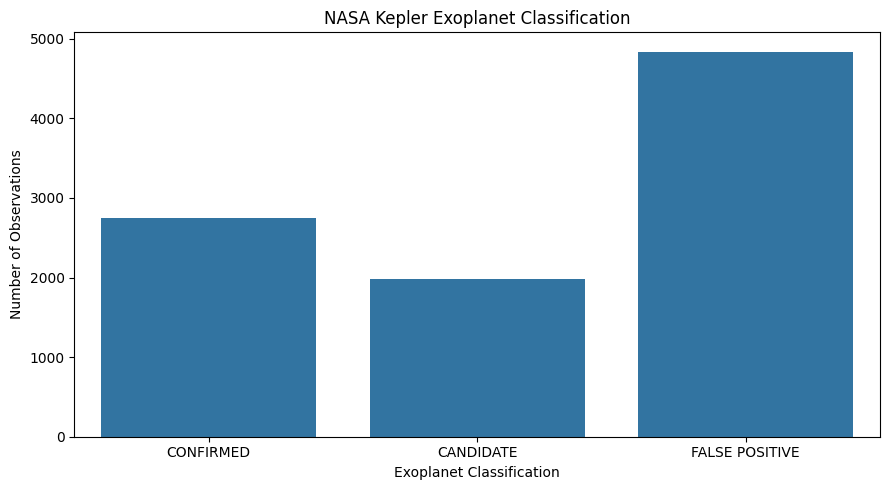

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data= data,
    x="koi_disposition",
    order=[
        "CONFIRMED",
        "CANDIDATE",
        "FALSE POSITIVE"
    ]
)

plt.title("NASA Kepler Exoplanet Classification")
plt.xlabel("Exoplanet Classification")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()


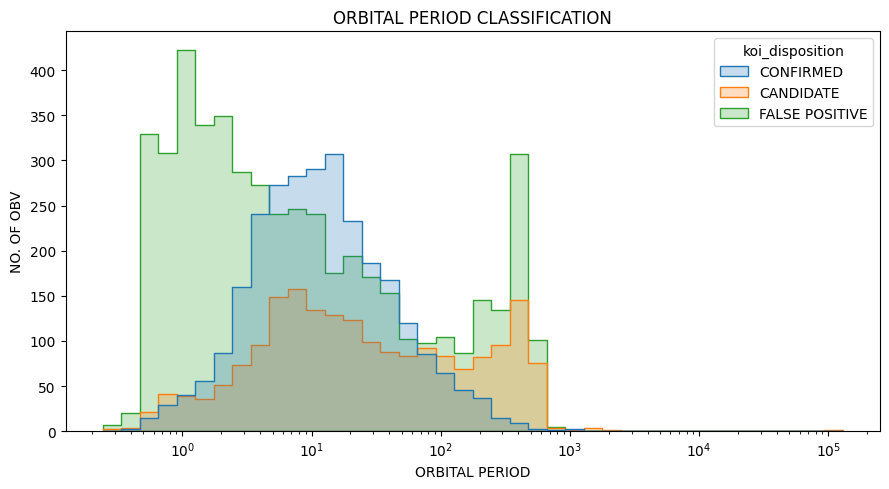

In [5]:
#do confiremed , candidate and false positive results have thier orbitals legit 

orbital_data = data[data["koi_period"]>0].copy()

plt.figure(figsize = (9,5))

sns.histplot(
    data = orbital_data,
    x = "koi_period",
    hue = "koi_disposition",
    bins = 40,
    log_scale = True,
    element = "step"
)

plt.title("ORBITAL PERIOD CLASSIFICATION")
plt.xlabel("ORBITAL PERIOD")
plt.ylabel("NO. OF OBV")

plt.tight_layout()
plt.show()

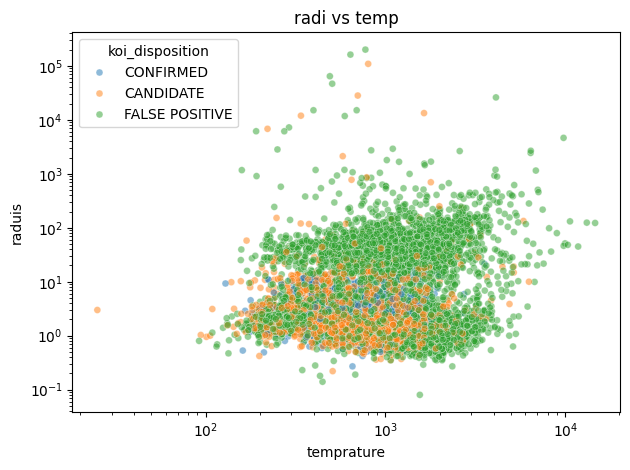

In [8]:
#now we will see if the planet temp and the raduis of the planet observed
# are how apart with the parameters of candidate , confirmed and false positive


scatter_data  = data[(data["koi_teq"]> 0 ) & (data["koi_prad"]> 0 )].copy()


plt.Figure(figsize=(9,5))

sns.scatterplot(data= scatter_data,
                x="koi_teq",
                y="koi_prad",
                hue="koi_disposition",
                alpha = 0.5,
                s = 25

            )

plt.xscale("log")
plt.yscale("log")
plt.title("radi vs temp")
plt.xlabel("temprature")
plt.ylabel("raduis")
plt.tight_layout()
plt.show()




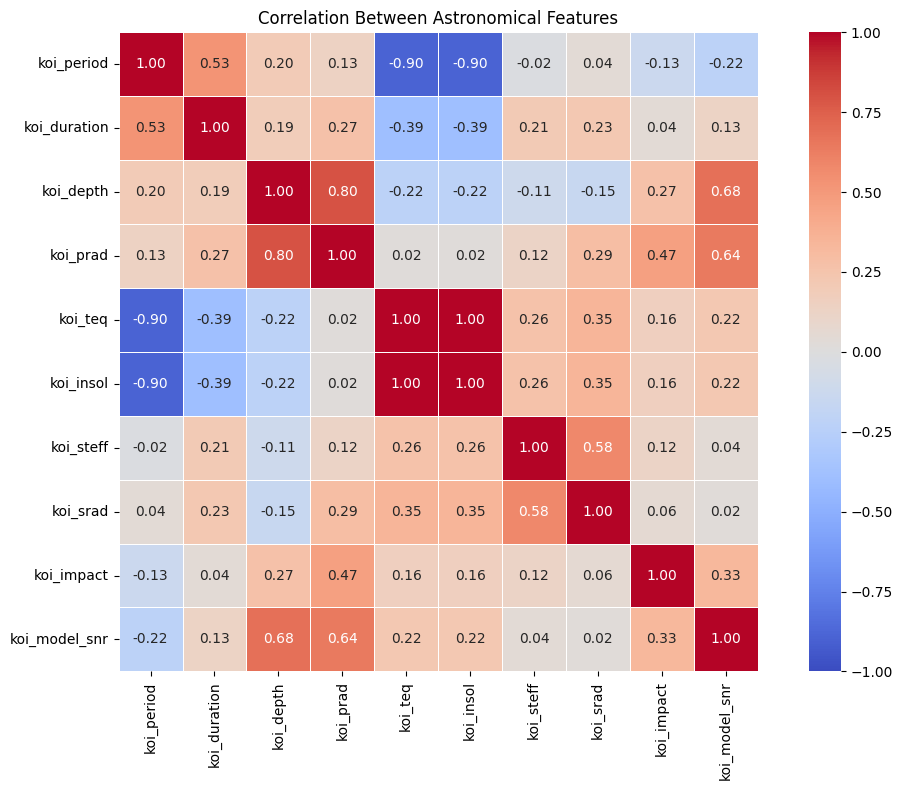

In [11]:
""" Now we will go for the corelation of all the major variable we are probably gonna use the list is 
koi_period	Orbital period
koi_duration	Transit duration
koi_depth	Transit depth
koi_prad	Planet radius
koi_teq	Equilibrium temperature
koi_insol	Insolation flux
koi_steff	Stellar temperature
koi_srad	Stellar radius
koi_impact	Impact parameter
koi_model_snr	Transit signal-to-noise ratio """


features = [
    "koi_period",
    "koi_duration",
    "koi_depth",
    "koi_prad",
    "koi_teq",
    "koi_insol",
    "koi_steff",
    "koi_srad",
    "koi_impact",
    "koi_model_snr"
]

# Select only the required columns
correlation_data = data[features].copy()

# Calculate Spearman correlation
corr_matrix = correlation_data.corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Between Astronomical Features")
plt.tight_layout()
plt.show()




In [12]:
#now we will create a new dataframe from the given imp features 

model_data = data[["kepid","koi_disposition"]+ features].copy()

model_data.head()

,kepid,koi_disposition,koi_period,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_steff,koi_srad,koi_impact,koi_model_snr
0,10797460,CONFIRMED,9.488036,2.95750,615.8,2.26,793.0,93.59,5455.0,0.927,0.146,35.8
1,10797460,CONFIRMED,54.418383,4.50700,874.8,2.83,443.0,9.11,5455.0,0.927,0.586,25.8
2,10811496,CANDIDATE,19.899140,1.78220,10829.0,14.60,638.0,39.30,5853.0,0.868,0.969,76.3
3,10848459,FALSE POSITIVE,1.736952,2.40641,8079.2,33.46,1395.0,891.96,5805.0,0.791,1.276,505.6
4,10854555,CONFIRMED,2.525592,1.65450,603.3,2.75,1406.0,926.16,6031.0,1.046,0.701,40.9


In [14]:
model_data["target"] = model_data["koi_disposition"].map({"CONFIRMED":1,
                                                          "CANDIDATE":1,
                                                          "FALSE POSITIVE":0})


print(model_data[["koi_disposition","target"]].head(10))

print(model_data["target"].value_counts())

  koi_disposition  target
0       CONFIRMED       1
1       CONFIRMED       1
2       CANDIDATE       1
3  FALSE POSITIVE       0
4       CONFIRMED       1
5       CONFIRMED       1
6       CONFIRMED       1
7       CONFIRMED       1
8  FALSE POSITIVE       0
9       CONFIRMED       1
target
0    4839
1    4725
Name: count, dtype: int64


In [18]:
#missin data handaling 

missing_model_values = model_data[features].isnull().sum()

print(missing_model_values)


missing_model_values_percentage = (missing_model_values/len(model_data[features]))*100

print(missing_model_values_percentage)


missing_summary = pd.DataFrame({"missing values":missing_model_values,
                                "missing percentage":missing_model_values_percentage})


print(missing_summary)

print(missing_summary.sum())

koi_period         0
koi_duration       0
koi_depth        363
koi_prad         363
koi_teq          363
koi_insol        321
koi_steff        363
koi_srad         363
koi_impact       363
koi_model_snr    363
dtype: int64
koi_period       0.000000
koi_duration     0.000000
koi_depth        3.795483
koi_prad         3.795483
koi_teq          3.795483
koi_insol        3.356336
koi_steff        3.795483
koi_srad         3.795483
koi_impact       3.795483
koi_model_snr    3.795483
dtype: float64
               missing values  missing percentage
koi_period                  0            0.000000
koi_duration                0            0.000000
koi_depth                 363            3.795483
koi_prad                  363            3.795483
koi_teq                   363            3.795483
koi_insol                 321            3.356336
koi_steff                 363            3.795483
koi_srad                  363            3.795483
koi_impact                363            3.795483
ko

In [25]:
# now we validate our data

print("duplicate rows ",model_data.duplicated().sum())

print("unique host stars",model_data["kepid"].nunique())

print("target values",model_data["target"].unique())

print(model_data[features].dtypes)

print("dataset shape",model_data.shape)

duplicate rows  0
unique host stars 8214
target values [1 0]
koi_period       float64
koi_duration     float64
koi_depth        float64
koi_prad         float64
koi_teq          float64
koi_insol        float64
koi_steff        float64
koi_srad         float64
koi_impact       float64
koi_model_snr    float64
dtype: object
dataset shape (9564, 13)


In [ ]:
#save the model data in the directory
from pathlib import Path


output_path = Path("D:/exoplanet_hunter/data/model_data.csv")


output_path.parent.mkdir(parents=True, exist_ok=True)


model_data.to_csv(output_path, index=False)


print("Dataset saved successfully!")

print("File location:", output_path.resolve())



Dataset saved successfully!
File location: D:\exoplanet_hunter\data\model_data.csv
